   # Perspective projection
   ### A 3D point (X, Y, Z) projects to x = f·X/Z, y = f·Y/Z on the image plane.
   A camera has f = 50 mm. A point is at (xo, yo, zo) = (1 m, 0.5 m, 10 m).
   xi = 50 mm × 1 / 10 = 5.0 mm, yi = 50 mm × 0.5 / 10 = 2.5 mm from the image centre.
   If each pixel is 5 μm wide, that is 5 mm / 0.005 mm = 1000 px right and 500 px up from the
   centre.

In [4]:
import numpy as np
f_mm =  50.0
pixel_mm = 0.005

def project(P, f=f_mm):
    X,Y,Z = P
    return f*X/Z, f*Y/Z
x_mm, y_mm = project((1.0, 0.5, 10.0))
print(x_mm, y_mm)
print(x_mm/pixel_mm, y_mm/pixel_mm)

5.0 2.5
1000.0 500.0


### Worked example 2 · How tall is a pedestrian in the image, and how far away?
An automotive camera has f = 6 mm and 3 μm pixels. A 1.75 m pedestrian stands 20 m away.
Height on the sensor: hi = f · H / z = 6 mm × 1.75 / 20 = 0.525 mm → 0.525 / 0.003 = 175 px.
At 40 m the same person is only 88 px tall; at 80 m, 44 px.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

f_mm = 60
pixel_mm = 0.003
H_m = 1.75

def height_px(z_m, H=H_m, f=f_mm, p=pixel_mm):
    h_mm = f*H/z_m
    return h_mm/p

def distance_m(h_px, H=H_m, f=f_mm, p=pixel_mm):
    h_mm = h_px*p
    return f*H/h_mm

for z in [20, 40, 80]:
    print(f"{z:>3} m-> {height_px(z):6.1f} px")
print(f"100 px box -> {distance_m(100):.1f}m")

 20 m-> 1750.0 px
 40 m->  875.0 px
 80 m->  437.5 px
100 px box -> 350.0m


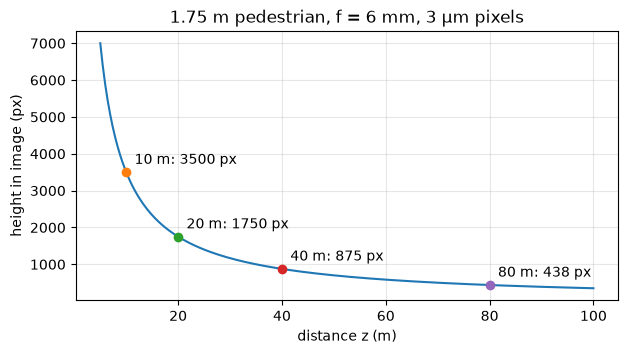

In [7]:
z = np.linspace(5, 100, 400)
plt.figure(figsize=(7, 3.5))
plt.plot(z, height_px(z))
for zz in [10, 20, 40, 80]:
    plt.plot(zz, height_px(zz), "o")
    plt.annotate(f"{zz} m: {height_px(zz):.0f} px", (zz, height_px(zz)),
                 xytext=(6, 6), textcoords="offset points")
plt.xlabel("distance z (m)")
plt.ylabel("height in image (px)")
plt.title("1.75 m pedestrian, f = 6 mm, 3 µm pixels")
plt.grid(alpha=0.3)
plt.show()